# Retail Sales & Returns Analysis

## Project Overview
This project analyses the sales and returns data of a retail business with 4 stores in the UAE (Dubai, Abu Dhabi, Sharjah and Ajman). The data covers about one year of sales (Oct 2024 - Oct 2025) and is spread over 5 CSV files.

## Objectives
- Combine the 5 tables into one dataset
- Find total sales, average purchase value, top products, top customers and best cities, stores and categories
- Measure the return rate, the total refund amount and the main reasons for returns
- Show the results with charts and write down the key insights

## Tools Used
Python, pandas, matplotlib, seaborn, Jupyter Notebook

## 1. Import Library and Load the Data
Import pandas and read the 5 CSV files: customers, products, stores, sales and returns.

In [1]:
import pandas as pd

In [2]:
customers = pd.read_csv("Customers.csv")
products = pd.read_csv("products.csv")
stores = pd.read_csv("stores.csv")
sales = pd.read_csv("sales.csv")
returns = pd.read_csv("returns.csv")

## 2. Understand the Data
Check the size (rows and columns) and the data types of the customers table.

In [3]:
customers.shape

(200, 6)

In [4]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   CustomerID  200 non-null    str  
 1   Name        200 non-null    str  
 2   Gender      200 non-null    str  
 3   Age         200 non-null    int64
 4   City        200 non-null    str  
 5   SignupDate  200 non-null    str  
dtypes: int64(1), str(5)
memory usage: 18.8 KB


## 3. Merge the Tables
All tables are merged into the `sales` table using left joins:
- sales + products on `ProductID`
- + customers on `CustomerID`
- + stores on `StoreID`

Both the customers and stores tables have a `City` column, so pandas renames them `City_x` (customer's city) and `City_y` (store's city).

In [ ]:
df = sales.merge(products, on="ProductID", how="left")
df

,SaleID,Date,ProductID,CustomerID,StoreID,Quantity,PaymentMode,ProductName,Category,Price
0,SL0001,2025-02-08,P002,C162,S002,4,Cash,Classic Watch,Watches,499
1,SL0002,2025-09-23,P001,C077,S002,2,Credit Card,Oud Perfume,Perfume,350
2,SL0003,2024-11-18,P008,C051,S003,1,Cash,Sports Watch,Watches,399
3,SL0004,2025-08-19,P003,C153,S002,5,Credit Card,Designer Sunglasses,Accessories,299
4,SL0005,2025-02-08,P007,C027,S003,1,Cash,Perfume Set,Perfume,450
...,...,...,...,...,...,...,...,...,...,...
1995,SL1996,2025-05-19,P003,C191,S002,5,Credit Card,Designer Sunglasses,Accessories,299
1996,SL1997,2024-10-29,P003,C127,S004,1,Credit Card,Designer Sunglasses,Accessories,299
1997,SL1998,2025-06-25,P003,C069,S002,5,Online,Designer Sunglasses,Accessories,299
1998,SL1999,2025-05-11,P007,C034,S001,2,Cash,Perfume Set,Perfume,450


In [ ]:
df = df.merge(customers, on="CustomerID", how="left")

# Merge with stores
df = df.merge(stores, on="StoreID", how="left")

# Check merged DataFrame
df.head()

,SaleID,Date,ProductID,CustomerID,StoreID,Quantity,PaymentMode,ProductName,Category,Price,Name,Gender,Age,City_x,SignupDate,StoreName,City_y,Manager
0,SL0001,2025-02-08,P002,C162,S002,4,Cash,Classic Watch,Watches,499,Omar Saeed Mcmillan,Male,36,Abu Dhabi,2023-05-20,Yas Mall Outlet,Abu Dhabi,Lina Farouk
1,SL0002,2025-09-23,P001,C077,S002,2,Credit Card,Oud Perfume,Perfume,350,Rami Al-Hamadi Rodriguez,Male,36,Abu Dhabi,2024-05-09,Yas Mall Outlet,Abu Dhabi,Lina Farouk
2,SL0003,2024-11-18,P008,C051,S003,1,Cash,Sports Watch,Watches,399,Maryam Al-Fahad Patterson,Female,30,Sharjah,2025-04-17,Sahara Center,Sharjah,Raza Ahmed
3,SL0004,2025-08-19,P003,C153,S002,5,Credit Card,Designer Sunglasses,Accessories,299,Aisha Al-Suwaidi Wagner,Male,21,Abu Dhabi,2023-05-17,Yas Mall Outlet,Abu Dhabi,Lina Farouk
4,SL0005,2025-02-08,P007,C027,S003,1,Cash,Perfume Set,Perfume,450,Khalid Al-Qassimi Perez,Male,43,Sharjah,2024-01-16,Sahara Center,Sharjah,Raza Ahmed


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   SaleID       2000 non-null   str  
 1   Date         2000 non-null   str  
 2   ProductID    2000 non-null   str  
 3   CustomerID   2000 non-null   str  
 4   StoreID      2000 non-null   str  
 5   Quantity     2000 non-null   int64
 6   PaymentMode  2000 non-null   str  
 7   ProductName  2000 non-null   str  
 8   Category     2000 non-null   str  
 9   Price        2000 non-null   int64
 10  Name         2000 non-null   str  
 11  Gender       2000 non-null   str  
 12  Age          2000 non-null   int64
 13  City_x       2000 non-null   str  
 14  SignupDate   2000 non-null   str  
 15  StoreName    2000 non-null   str  
 16  City_y       2000 non-null   str  
 17  Manager      2000 non-null   str  
dtypes: int64(3), str(15)
memory usage: 546.9 KB


## 4. Data Cleaning and Preparation
- Convert `SignupDate` to the date format
- Check for missing values
- Create a new column `TotalAmount = Quantity x Price`

In [ ]:
df['SignupDate']=pd.to_datetime(df['SignupDate'])

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   SaleID       2000 non-null   str           
 1   Date         2000 non-null   str           
 2   ProductID    2000 non-null   str           
 3   CustomerID   2000 non-null   str           
 4   StoreID      2000 non-null   str           
 5   Quantity     2000 non-null   int64         
 6   PaymentMode  2000 non-null   str           
 7   ProductName  2000 non-null   str           
 8   Category     2000 non-null   str           
 9   Price        2000 non-null   int64         
 10  Name         2000 non-null   str           
 11  Gender       2000 non-null   str           
 12  Age          2000 non-null   int64         
 13  City_x       2000 non-null   str           
 14  SignupDate   2000 non-null   datetime64[us]
 15  StoreName    2000 non-null   str           
 16  City_y       2000

In [ ]:
# Check merged DataFrame
df.head()

,SaleID,Date,ProductID,CustomerID,StoreID,Quantity,PaymentMode,ProductName,Category,Price,Name,Gender,Age,City_x,SignupDate,StoreName,City_y,Manager
0,SL0001,2025-02-08,P002,C162,S002,4,Cash,Classic Watch,Watches,499,Omar Saeed Mcmillan,Male,36,Abu Dhabi,2023-05-20,Yas Mall Outlet,Abu Dhabi,Lina Farouk
1,SL0002,2025-09-23,P001,C077,S002,2,Credit Card,Oud Perfume,Perfume,350,Rami Al-Hamadi Rodriguez,Male,36,Abu Dhabi,2024-05-09,Yas Mall Outlet,Abu Dhabi,Lina Farouk
2,SL0003,2024-11-18,P008,C051,S003,1,Cash,Sports Watch,Watches,399,Maryam Al-Fahad Patterson,Female,30,Sharjah,2025-04-17,Sahara Center,Sharjah,Raza Ahmed
3,SL0004,2025-08-19,P003,C153,S002,5,Credit Card,Designer Sunglasses,Accessories,299,Aisha Al-Suwaidi Wagner,Male,21,Abu Dhabi,2023-05-17,Yas Mall Outlet,Abu Dhabi,Lina Farouk
4,SL0005,2025-02-08,P007,C027,S003,1,Cash,Perfume Set,Perfume,450,Khalid Al-Qassimi Perez,Male,43,Sharjah,2024-01-16,Sahara Center,Sharjah,Raza Ahmed


In [ ]:
# Check for missing values
print(df.isnull().sum())

SaleID         0
Date           0
ProductID      0
CustomerID     0
StoreID        0
Quantity       0
PaymentMode    0
ProductName    0
Category       0
Price          0
Name           0
Gender         0
Age            0
City_x         0
SignupDate     0
StoreName      0
City_y         0
Manager        0
dtype: int64


In [ ]:
df['TotalAmount'] = df['Quantity'] * df['Price']
df.head()

,SaleID,Date,ProductID,CustomerID,StoreID,Quantity,PaymentMode,ProductName,Category,Price,Name,Gender,Age,City_x,SignupDate,StoreName,City_y,Manager,TotalAmount
0,SL0001,2025-02-08,P002,C162,S002,4,Cash,Classic Watch,Watches,499,Omar Saeed Mcmillan,Male,36,Abu Dhabi,2023-05-20,Yas Mall Outlet,Abu Dhabi,Lina Farouk,1996
1,SL0002,2025-09-23,P001,C077,S002,2,Credit Card,Oud Perfume,Perfume,350,Rami Al-Hamadi Rodriguez,Male,36,Abu Dhabi,2024-05-09,Yas Mall Outlet,Abu Dhabi,Lina Farouk,700
2,SL0003,2024-11-18,P008,C051,S003,1,Cash,Sports Watch,Watches,399,Maryam Al-Fahad Patterson,Female,30,Sharjah,2025-04-17,Sahara Center,Sharjah,Raza Ahmed,399
3,SL0004,2025-08-19,P003,C153,S002,5,Credit Card,Designer Sunglasses,Accessories,299,Aisha Al-Suwaidi Wagner,Male,21,Abu Dhabi,2023-05-17,Yas Mall Outlet,Abu Dhabi,Lina Farouk,1495
4,SL0005,2025-02-08,P007,C027,S003,1,Cash,Perfume Set,Perfume,450,Khalid Al-Qassimi Perez,Male,43,Sharjah,2024-01-16,Sahara Center,Sharjah,Raza Ahmed,450


## 5. Sales Analysis
Total sales, average purchase, top products and customers, and sales by city, gender, category and store.

In [ ]:

# Total Sales Amount
total_sales=df['TotalAmount'].sum()
print("Total_sales:",total_sales)

Total_sales: 2215122


In [ ]:
#Average Purchase Amount per Transaction
Avg_amount=df['TotalAmount'].mean()
print("Avg_amount:",Avg_amount)

Avg_amount: 1107.561


In [ ]:
#top 5 product
Top_5_product=df.groupby('ProductName')['TotalAmount'].sum().sort_values(ascending= False).head()
print("--Top 5 Products -- \n",Top_5_product)

--Top 5 Products -- 
 ProductName
Luxury Bag       392944
Classic Watch    375747
Perfume Set      351000
Sports Watch     296058
Oud Perfume      275450
Name: TotalAmount, dtype: int64


In [ ]:
#top 5 customer who spend most
top_5_customers=df.groupby('CustomerID')['TotalAmount'].sum().sort_values(ascending= False).head()
print(top_5_customers)

CustomerID
C058    22312
C064    22066
C158    21224
C142    20955
C191    20767
Name: TotalAmount, dtype: int64


In [ ]:
#Total sales by city and sort descending
top_city=df.groupby('City_x')['TotalAmount'].sum().sort_values(ascending=False).head()
print("Total sales by city:")
print(top_city)

Total sales by city:
City_x
Ajman        621401
Dubai        610892
Abu Dhabi    499837
Sharjah      482992
Name: TotalAmount, dtype: int64


In [ ]:
#Sales by Gender
SalesbyGender=df.groupby('Gender')['TotalAmount'].sum()
print("Sales by Gender:")
print(SalesbyGender)

Sales by Gender:
Gender
Female    1142741
Male      1072381
Name: TotalAmount, dtype: int64


In [ ]:
#Sales by Product Category
sales_by_category = df.groupby('Category')['TotalAmount'].sum().sort_values(ascending=False)
print("Sales by Category:")
print(sales_by_category)

Sales by Category:
Category
Accessories    766025
Watches        671805
Perfume        626450
Electronics    150842
Name: TotalAmount, dtype: int64


In [ ]:
#Highest sales by store
Highestsalebystore=df.groupby('StoreName')['TotalAmount'].sum().sort_values(ascending=False).head()
print("Highest sales by store:")
print(Highestsalebystore)

Highest sales by store:
StoreName
City Center Ajman    621401
Dubai Mall Outlet    610892
Yas Mall Outlet      499837
Sahara Center        482992
Name: TotalAmount, dtype: int64


In [ ]:
#Average Quantity Sold per Category
avg_qty_category = df.groupby('Category')['Quantity'].mean().round(2)
print("Average Quantity Sold per Category:")
print(avg_qty_category)

Average Quantity Sold per Category:
Category
Accessories    3.14
Electronics    2.95
Perfume        3.04
Watches        2.99
Name: Quantity, dtype: float64


In [ ]:
#Unique Customers per city
unique_customers=df.groupby('City_x')['CustomerID'].nunique()
print("unique customers per city:")
print(unique_customers)
    

unique customers per city:
City_x
Abu Dhabi    44
Ajman        55
Dubai        55
Sharjah      46
Name: CustomerID, dtype: int64


### Key Findings: Sales Analysis
- **No missing values** in the merged data, and all 2,000 sales rows were kept after merging.
- **Total sales** are 2,215,122 and the **average purchase** per transaction is 1,107.56.
- **Top 3 products:** Luxury Bag (392,944), Classic Watch (375,747) and Perfume Set (351,000). Together they make up about 51% of all sales.
- **Top category:** Accessories (766,025, about 35% of sales). Electronics is the lowest (150,842, about 7%).
- **Cities and stores:** Ajman (621,401) and Dubai (610,892) are the top cities, while Abu Dhabi and Sharjah are each about 22% of sales.
- **Gender:** Female customers spend slightly more (1,142,741) than male customers (1,072,381).
- **Top customers:** The top 5 customers each spend about 21,000 - 22,000, so no single customer dominates sales.
- **Average quantity** per sale is about 3 in every category.

## 6. Returns Analysis
Merge the returns table with the sales data on `SaleID`, then find the total refund amount, the reasons for returns, the return rate, the return rate by category and the customers with the most returns.

In [ ]:
import pandas as pd

In [ ]:
#Returns Analysis
returns_df=pd.read_csv("returns.csv")
returns_df

,ReturnID,SaleID,ReturnDate,Reason,RefundAmount
0,R1275,SL1275,2024-12-16,Defective,598
1,R1569,SL1569,2025-03-13,Wrong Item,750
2,R1131,SL1131,2025-01-19,Defective,2250
3,R0082,SL0082,2025-03-30,Defective,597
4,R0080,SL0080,2025-07-09,Defective,1596
...,...,...,...,...,...
135,R0935,SL0935,2025-10-02,Wrong Item,299
136,R1659,SL1659,2025-07-23,Defective,700
137,R0318,SL0318,2025-03-10,Wrong Item,499
138,R1549,SL1549,2025-08-17,Defective,2995


In [ ]:
#Merge return table with Sales table
merge_df=pd.merge(df,returns_df,on='SaleID',how='left')
print(merge_df.head())
                  

   SaleID        Date ProductID CustomerID StoreID  Quantity  PaymentMode  \
0  SL0001  2025-02-08      P002       C162    S002         4         Cash   
1  SL0002  2025-09-23      P001       C077    S002         2  Credit Card   
2  SL0003  2024-11-18      P008       C051    S003         1         Cash   
3  SL0004  2025-08-19      P003       C153    S002         5  Credit Card   
4  SL0005  2025-02-08      P007       C027    S003         1         Cash   

           ProductName     Category  Price  ...     City_x SignupDate  \
0        Classic Watch      Watches    499  ...  Abu Dhabi 2023-05-20   
1          Oud Perfume      Perfume    350  ...  Abu Dhabi 2024-05-09   
2         Sports Watch      Watches    399  ...    Sharjah 2025-04-17   
3  Designer Sunglasses  Accessories    299  ...  Abu Dhabi 2023-05-17   
4          Perfume Set      Perfume    450  ...    Sharjah 2024-01-16   

         StoreName     City_y      Manager TotalAmount ReturnID ReturnDate  \
0  Yas Mall Outlet  

In [ ]:
print(merge_df.head())

   SaleID        Date ProductID CustomerID StoreID  Quantity  PaymentMode  \
0  SL0001  2025-02-08      P002       C162    S002         4         Cash   
1  SL0002  2025-09-23      P001       C077    S002         2  Credit Card   
2  SL0003  2024-11-18      P008       C051    S003         1         Cash   
3  SL0004  2025-08-19      P003       C153    S002         5  Credit Card   
4  SL0005  2025-02-08      P007       C027    S003         1         Cash   

           ProductName     Category  Price  ...     City_x SignupDate  \
0        Classic Watch      Watches    499  ...  Abu Dhabi 2023-05-20   
1          Oud Perfume      Perfume    350  ...  Abu Dhabi 2024-05-09   
2         Sports Watch      Watches    399  ...    Sharjah 2025-04-17   
3  Designer Sunglasses  Accessories    299  ...  Abu Dhabi 2023-05-17   
4          Perfume Set      Perfume    450  ...    Sharjah 2024-01-16   

         StoreName     City_y      Manager TotalAmount ReturnID ReturnDate  \
0  Yas Mall Outlet  

In [ ]:
merge_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   SaleID        2000 non-null   str           
 1   Date          2000 non-null   str           
 2   ProductID     2000 non-null   str           
 3   CustomerID    2000 non-null   str           
 4   StoreID       2000 non-null   str           
 5   Quantity      2000 non-null   int64         
 6   PaymentMode   2000 non-null   str           
 7   ProductName   2000 non-null   str           
 8   Category      2000 non-null   str           
 9   Price         2000 non-null   int64         
 10  Name          2000 non-null   str           
 11  Gender        2000 non-null   str           
 12  Age           2000 non-null   int64         
 13  City_x        2000 non-null   str           
 14  SignupDate    2000 non-null   datetime64[us]
 15  StoreName     2000 non-null   str           
 16 

In [ ]:
merge_df.isnull().sum()

SaleID             0
Date               0
ProductID          0
CustomerID         0
StoreID            0
Quantity           0
PaymentMode        0
ProductName        0
Category           0
Price              0
Name               0
Gender             0
Age                0
City_x             0
SignupDate         0
StoreName          0
City_y             0
Manager            0
TotalAmount        0
ReturnID        1860
ReturnDate      1860
Reason          1860
RefundAmount    1860
dtype: int64

In [ ]:
#Find Total Refund Amount
# Some sales may not be returned, so RefundAmount could have NaN — fill with 0
merge_df['RefundAmount'] = merge_df['RefundAmount'].fillna(0)

total_refund = merge_df['RefundAmount'].sum()
print(" Total Refund Amount:", total_refund)

 Total Refund Amount: 170327.0


In [ ]:
#Count of Returns by Reason
returns_reason = merge_df['Reason'].value_counts().reset_index()
returns_reason.columns = ['Reason', 'Count']
print(" Count of Returns by Reason:")
returns_reason

 Count of Returns by Reason:


,Reason,Count
0,Changed Mind,49
1,Wrong Item,49
2,Defective,42


In [ ]:
#Return Rate (%)
# Number of returns
num_returns = merge_df['ReturnID'].notnull().sum()

# Total sales count
total_sales = merge_df['SaleID'].nunique()

return_rate = (num_returns / total_sales) * 100
print(f" Return Rate: {return_rate:.2f}%")

 Return Rate: 7.00%


In [ ]:
#Product Category with Highest Return Rate
# Returns by category
returns_by_category = merge_df.groupby('Category')['ReturnID'].count()

# Total sales by category
sales_by_category = merge_df.groupby('Category')['SaleID'].count()

# Return rate by category
category_return_rate = (returns_by_category / sales_by_category * 100).reset_index()
category_return_rate.columns = ['Category', 'ReturnRate']

# Sort and show top
top_category = category_return_rate.sort_values(by='ReturnRate', ascending=False)
top_category

,Category,ReturnRate
2,Perfume,7.945736
3,Watches,7.600000
0,Accessories,6.602476
1,Electronics,5.058366


In [ ]:
#Top 3 Customers Who Made the Most Returns
top_customers = merge_df.groupby('CustomerID')['ReturnID'].count().sort_values(ascending=False).head(3).reset_index()
top_customers.columns = ['CustomerID', 'NumberOfReturns']
print(" Top 3 Customers with Most Returns:")
print(top_customers)

 Top 3 Customers with Most Returns:
  CustomerID  NumberOfReturns
0       C128                5
1       C200                4
2       C056                3


### Key Findings: Returns Analysis
- Only **140 out of 2,000 sales** were returned, so the **return rate is 7.00%**.
- The **total refund amount is 170,327**, which is about 7.7% of total sales.
- **Perfume** has the highest return rate (7.95%), followed by Watches (7.60%), Accessories (6.60%) and Electronics (5.06%).
- **Reasons for returns:** Changed Mind (49), Wrong Item (49) and Defective (42) are almost equal.
- **Customer C128** made the most returns (5), followed by C200 (4) and C179 (3).

## 7. Data Visualization
Charts for sales by city, gender share, top products, monthly trend, return reasons and the correlation between the numerical columns.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


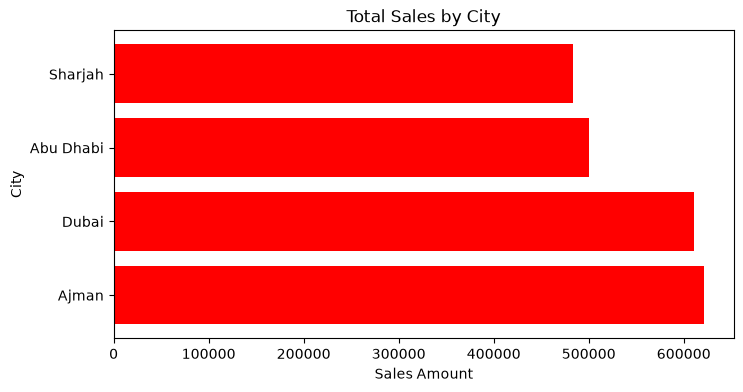

In [ ]:
sales_city = merge_df.groupby('City_x')['TotalAmount'].sum().sort_values(ascending=False)
plt.figure(figsize=(8,4))
plt.barh(sales_city.index,sales_city.values, color="Red" )
plt.title("Total Sales by City")
plt.xlabel("Sales Amount")
plt.ylabel("City")
plt.show()

In [ ]:
merge_df.groupby('City_x')['TotalAmount'].sum().sort_values(ascending=False)

City_x
Ajman        621401
Dubai        610892
Abu Dhabi    499837
Sharjah      482992
Name: TotalAmount, dtype: int64

**Insight:** Ajman and Dubai are the top cities with about 28% of sales each. Abu Dhabi and Sharjah are each about 22%, so sales are fairly well spread across the cities.

In [ ]:
sales_gender=merge_df.groupby('Gender')['TotalAmount'].sum().sort_values(ascending=False)
print(sales_gender)

Gender
Female    1142741
Male      1072381
Name: TotalAmount, dtype: int64


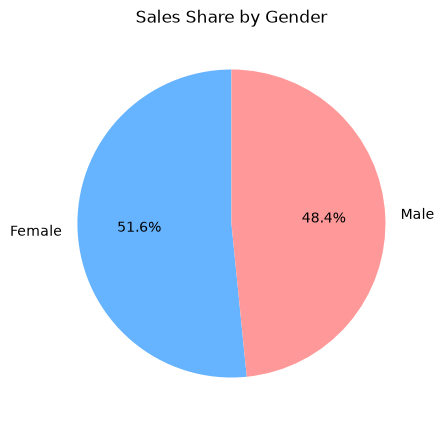

In [ ]:

#Pie Chart – Sales Share by Gender
sales_gender = merge_df.groupby('Gender')['TotalAmount'].sum()

plt.figure(figsize=(5,5))
plt.pie(sales_gender.values, labels=sales_gender.index, autopct='%1.1f%%', startangle=90, colors=['#66b3ff','#ff9999'])
plt.title("Sales Share by Gender")
plt.show()

**Insight:** Sales are almost balanced between genders: female customers contribute 51.6% and male customers 48.4%.

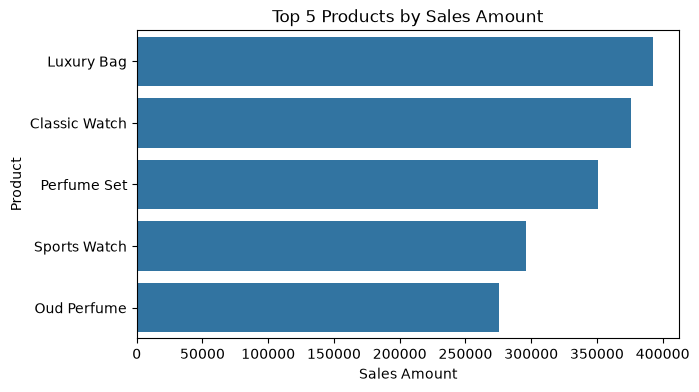

In [ ]:
#Bar Chart – Top 5 Products by Sales Amount
top_products = merge_df.groupby('ProductName')['TotalAmount'].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(7,4))
sns.barplot(x=top_products.values, y=top_products.index)
plt.title("Top 5 Products by Sales Amount")
plt.xlabel("Sales Amount")
plt.ylabel("Product")
plt.show()

**Insight:** Luxury Bag is the best-selling product, and all of the top 5 products are above 275,000 in sales. High-priced products bring in most of the revenue.

In [ ]:
#Line Chart – Monthly Sales Trend
# Ensure OrderDate is datetime type
merge_df['Date'] = pd.to_datetime(merge_df['Date'])
monthly_sales = merge_df.groupby(pd.Grouper(key='Date', freq='ME'))['TotalAmount'].sum().reset_index()
monthly_sales

,Date,TotalAmount
0,2024-10-31,40876
1,2024-11-30,177715
2,2024-12-31,173956
3,2025-01-31,189130
4,2025-02-28,182003
5,2025-03-31,178097
6,2025-04-30,209328
7,2025-05-31,166860
8,2025-06-30,199951
9,2025-07-31,186458


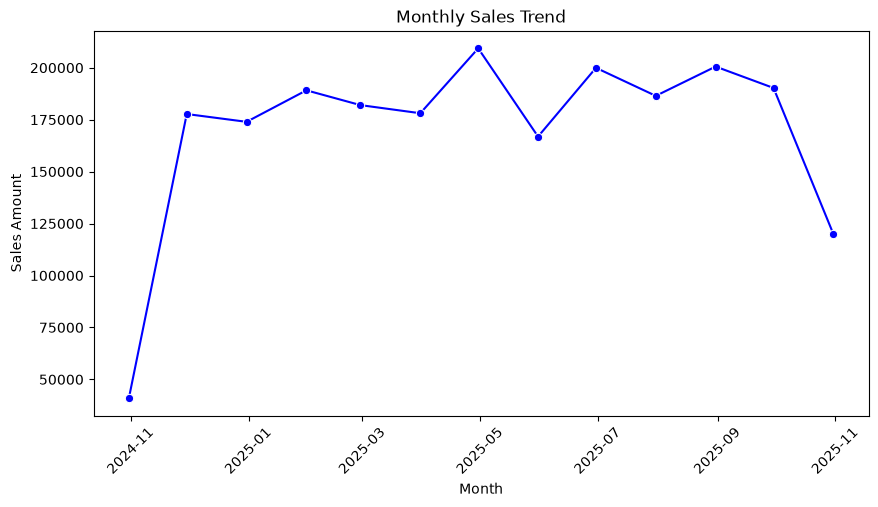

In [ ]:
#Line Chart – Monthly Sales Trend
# Ensure OrderDate is datetime type
merge_df['Date'] = pd.to_datetime(merge_df['Date'])
monthly_sales = merge_df.groupby(pd.Grouper(key='Date', freq='ME'))['TotalAmount'].sum().reset_index()

plt.figure(figsize=(10,5))
sns.lineplot(x='Date', y='TotalAmount', data=monthly_sales, marker='o', color='blue')
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.show()

**Insight:** Monthly sales stay between about 167,000 and 209,000 from Nov 2024 to Sep 2025. The peak is in April 2025 (209,328) and there is a small dip in May 2025. October 2024 and October 2025 look low, most likely because the data covers only part of those months.

In [ ]:
#Bar Chart – Number of Returns by Reason
returns_reason = merge_df['Reason'].value_counts().reset_index()
returns_reason.columns = ['Reason', 'Count']
returns_reason

,Reason,Count
0,Changed Mind,49
1,Wrong Item,49
2,Defective,42


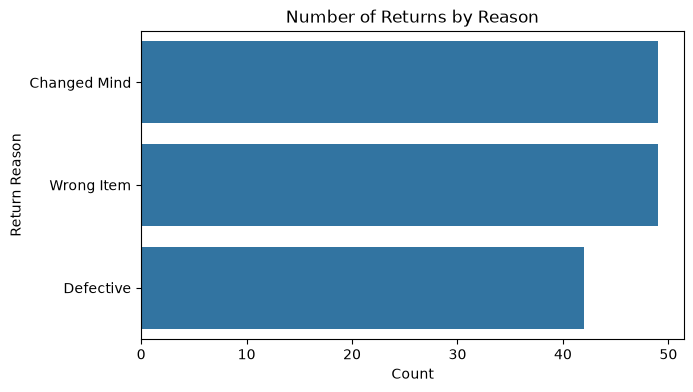

In [ ]:
#Bar Chart – Number of Returns by Reason
returns_reason = merge_df['Reason'].value_counts().reset_index()
returns_reason.columns = ['Reason', 'Count']

plt.figure(figsize=(7,4))
sns.barplot(x='Count', y='Reason', data=returns_reason)
plt.title("Number of Returns by Reason")
plt.xlabel("Count")
plt.ylabel("Return Reason")
plt.show()

**Insight:** Changed Mind and Wrong Item are tied at 49 returns each, and Defective has 42. Wrong Item returns could be reduced by improving order picking and packing.

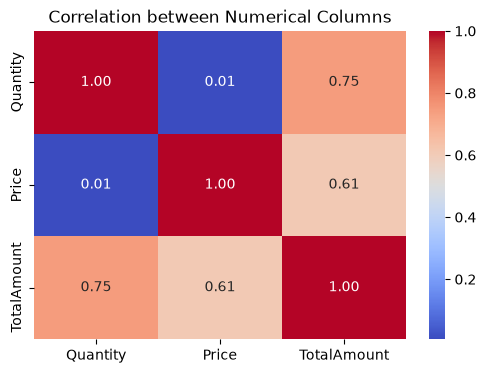

In [ ]:
#Correlation Heatmap
# Select only numerical columns
num_cols = ['Quantity', 'Price', 'TotalAmount']

plt.figure(figsize=(6,4))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation between Numerical Columns")
plt.show()

**Insight:** `TotalAmount` is calculated as Quantity x Price, so it is positively correlated with both Quantity (0.75) and Price (0.61). Quantity and Price are almost unrelated to each other (0.01), which means customers do not buy fewer items when the price is higher.

---

## 8. Conclusion
1. **Sales:** Total sales are 2,215,122 across 4 stores. Ajman and Dubai lead slightly, and the top 3 products (Luxury Bag, Classic Watch, Perfume Set) bring in about half of the revenue.
2. **Returns:** The return rate is 7% and refunds cost 170,327. Perfume and Watches are returned the most, and Wrong Item and Changed Mind are the most common reasons.
3. **Recommendation:** Check order picking and packing to reduce Wrong Item returns, and look at why Electronics sells much less (about 7% of sales) than the other categories.